# Multiclass Logistic Regression: What Predicts a Student's Performance Level?

**Template notebook.** Replace the dataset, research question and variable names with your own; keep the structure.

## 1. Research question

**Which student habits and characteristics predict whether a student ends up in the Low, Medium or High performance level, and which matter most?**

Sub-questions:
- How does one more hour of weekly study change the odds of reaching Medium or High instead of Low?
- Are study habits (hours, attendance, sleep, study groups) or background (prior GPA, work, commute) more important?
- How accurately can the model sort new students into the three levels?

**Why multiclass (multinomial) logistic regression?** The outcome (`performance_level`) is a category with three values. The model estimates the probability of each level and compares Medium and High with a reference level (Low).

## 2. The dataset

`student_performance.csv`: 600 students, one row per student.

| Column | Type | Meaning |
| --- | --- | --- |
| student_id | text | Student ID (not used in the model) |
| major | category | Business, Data Science, Engineering, Health, Humanities |
| study_hours_week | numeric | Hours spent studying per week |
| attendance_pct | numeric | % of classes attended |
| prior_gpa | numeric | GPA before the course (0–4) |
| sleep_hours | numeric | Average hours of sleep per night |
| works_part_time | 0/1 | 1 = has a part-time job |
| work_hours_week | numeric | Hours worked per week (0 if no job) |
| commute_minutes | numeric | One-way commute time, minutes |
| study_group | 0/1 | 1 = attends a study group |
| first_generation | 0/1 | 1 = first-generation college student |
| final_exam_score | numeric | Final exam score, 0–100 (**target for linear regression**) |
| performance_level | category | Low / Medium / High (**target for multiclass logistic regression**) |

*The data is simulated for teaching; it is realistic but not real.*

#### Cell: Import the libraries

**What this cell does.** Loads the Python packages the notebook needs and sets display options. Run this cell first, every time you open the notebook.

**The code, line by line:**
- `pandas` (as `pd`): tables of data (DataFrames) — reading CSVs, filtering, grouping, summarizing.
- `numpy` (as `np`): fast math on numbers and arrays (square roots, logs, exponentials).
- `matplotlib.pyplot` (as `plt`) and `seaborn` (as `sns`): plotting. Seaborn builds nicer statistical charts on top of matplotlib.
- `statsmodels.api` (as `sm`) and `statsmodels.formula.api` (as `smf`): statistical models. `smf` lets us write models as formulas like `y ~ x1 + x2`, the same style used in R.
- `variance_inflation_factor`: measures multicollinearity (Section 7).
- `train_test_split` from scikit-learn: splits the data into training and test sets.
- `pd.set_option("display.max_columns", None)` shows every column instead of hiding some with `...`.
- `sns.set_theme(style="whitegrid")` gives all charts a clean white background with light grid lines.

**Why it matters.** If an import fails with `ModuleNotFoundError`, the package is not installed. Install it with `pip install statsmodels seaborn scikit-learn` (or `%pip install ...` inside the notebook) and run the cell again.

**How to read the output.** This cell prints nothing when it works. No output = success.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score

## 3. Exploratory data analysis (EDA)

### 3.1 First look

#### Cell: Load the dataset

**What this cell does.** Reads the CSV file into a DataFrame called `df`, prints its size, and shows the first five rows.

**The code, line by line:**
- `pd.read_csv("student_performance.csv")` reads the file. It must be in the **same folder** as the notebook; otherwise give the full path, e.g. `pd.read_csv("data/student_performance.csv")`.
- `df.shape` returns `(rows, columns)`.
- `df.head()` shows the first 5 rows (`df.head(10)` shows 10). Because it is the last line of the cell, Jupyter displays it automatically.

**Why it matters.** Always look at the raw data before analyzing it. Check that columns loaded correctly, values look sensible, and you understand what one row represents.

**How to read the output.** The shape should be **(600, 13)**: 600 students and 13 columns. Each row is one student. `NaN` in the table means a missing value.

In [2]:
df = pd.read_csv("student_performance.csv")
print(df.shape)
df.head()

(600, 13)


,student_id,major,study_hours_week,attendance_pct,prior_gpa,sleep_hours,works_part_time,work_hours_week,commute_minutes,study_group,first_generation,final_exam_score,performance_level
0,S0001,Business,6.9,NaN,2.21,5.0,1,22.0,30.0,1,0,51.4,Low
1,S0002,Engineering,8.5,83.0,3.09,7.0,1,16.0,8.0,1,1,70.9,Medium
2,S0003,Engineering,12.0,100.0,2.76,6.3,1,15.0,8.0,1,1,74.6,Medium
3,S0004,Data Science,6.6,77.0,2.58,6.2,0,0.0,74.0,1,1,76.0,Medium
4,S0005,Data Science,5.2,90.0,3.18,5.2,0,0.0,20.0,1,0,80.5,Medium


#### Cell: Column types and non-missing counts

**What this cell does.** Lists every column with its data type and how many non-missing values it has.

**The code, line by line:**
- `df.info()` prints the column name, the **Non-Null Count** (values that are not missing) and the **Dtype** (data type).
- Common types: `int64` (whole numbers), `float64` (decimals, and also whole-number columns that contain missing values), `object` or `str` (text).

**Why it matters.** Wrong data types cause errors later. For example, a number column read as text (because of a stray symbol like "N/A") cannot be averaged or used in a model.

**How to read the output.** All 600 rows are present. Four columns have fewer than 600 non-null values, which means they have missing data: `attendance_pct` (588), `prior_gpa` (591), `sleep_hours` (573) and `commute_minutes` (582). `major`, `student_id` and `performance_level` are text; the rest are numeric. The 0/1 columns (`works_part_time`, `study_group`, `first_generation`) are stored as integers, which is what the models need.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   student_id         600 non-null    str    
 1   major              600 non-null    str    
 2   study_hours_week   600 non-null    float64
 3   attendance_pct     588 non-null    float64
 4   prior_gpa          591 non-null    float64
 5   sleep_hours        573 non-null    float64
 6   works_part_time    600 non-null    int64  
 7   work_hours_week    600 non-null    float64
 8   commute_minutes    582 non-null    float64
 9   study_group        600 non-null    int64  
 10  first_generation   600 non-null    int64  
 11  final_exam_score   600 non-null    float64
 12  performance_level  600 non-null    str    
dtypes: float64(7), int64(3), str(3)
memory usage: 61.1 KB


#### Cell: Summary statistics

**What this cell does.** Computes the count, mean, standard deviation, minimum, quartiles and maximum of every numeric column.

**The code, line by line:**
- `df.describe()` summarizes numeric columns only (text columns are skipped).
- `.round(2)` rounds to 2 decimals so the table is easier to read.
- **25% / 50% / 75%** are the quartiles; 50% is the **median**.

**Why it matters.** Summary statistics reveal typos and impossible values (a GPA of 7, negative hours), show the scale of each variable, and hint at skew: when the mean is far from the median, the distribution is lopsided.

**How to read the output.** Values are all in sensible ranges: study hours 1.2–29.1 per week (mean 8.8), attendance 57–100%, prior GPA 1.5–4.0 (mean 3.0), sleep 4–10 hours (mean 7.0), commute 1–117 minutes (mean 24, median 20), final exam score 41.8–100 (mean 74.4, SD 9.9). Commute and study hours have means above their medians, so they are **right-skewed** (a few students with very long commutes or many study hours). For 0/1 columns the mean is the share of 1s: 47% work part-time, 36% are in a study group, 32% are first-generation.

In [4]:
df.describe().round(2)

,study_hours_week,attendance_pct,prior_gpa,sleep_hours,works_part_time,work_hours_week,commute_minutes,study_group,first_generation,final_exam_score
count,600.00,588.00,591.00,573.00,600.00,600.00,582.00,600.00,600.00,600.00
mean,8.77,84.39,2.99,7.01,0.47,8.69,24.18,0.36,0.32,74.43
std,4.22,9.18,0.51,1.08,0.50,10.29,17.19,0.48,0.47,9.91
min,1.20,57.00,1.50,4.00,0.00,0.00,1.00,0.00,0.00,41.80
25%,5.60,78.00,2.62,6.20,0.00,0.00,12.00,0.00,0.00,67.88
50%,8.15,84.00,3.03,7.00,0.00,0.00,20.00,0.00,0.00,74.70
75%,11.30,91.00,3.36,7.70,1.00,18.25,32.00,1.00,1.00,80.70
max,29.10,100.00,4.00,10.00,1.00,35.00,117.00,1.00,1.00,100.00


### 3.2 Missing values and duplicates

#### Cell: Count missing values

**What this cell does.** Builds a small table with the number and percentage of missing values in each column, and shows only columns with at least one gap.

**The code, line by line:**
- `df.isna()` gives True where a value is missing; `.sum()` counts the Trues per column (True counts as 1).
- `df.isna().mean() * 100` is the **percentage** missing (the mean of True/False is the share of Trues).
- `missing[missing.missing > 0]` keeps only columns with gaps; `.sort_values(..., ascending=False)` puts the worst first.

**Why it matters.** Models in statsmodels silently **drop every row with a missing value** in any variable used. Knowing where the gaps are lets you decide deliberately how to handle them instead of losing data without noticing.

**How to read the output.** Four columns have gaps: `sleep_hours` 27 (4.5%), `commute_minutes` 18 (3.0%), `attendance_pct` 12 (2.0%) and `prior_gpa` 9 (1.5%). All are below 5%, which is small. A common rule of thumb: under about 5% missing, simple fixes like filling with the median are reasonable; above 20–30%, think harder about *why* data is missing.

In [5]:
missing = pd.DataFrame({"missing": df.isna().sum(), "percent": (df.isna().mean() * 100).round(1)})
missing[missing.missing > 0].sort_values("missing", ascending=False)

,missing,percent
sleep_hours,27,4.5
commute_minutes,18,3.0
attendance_pct,12,2.0
prior_gpa,9,1.5


#### Cell: Plot the missing values

**What this cell does.** Draws a horizontal bar chart of the percentage missing per column.

**The code, line by line:**
- `.plot(kind="barh")` makes horizontal bars directly from the pandas table.
- `plt.xlabel` and `plt.title` label the chart; `plt.show()` displays it.

**Why it matters.** A chart makes it easy to spot which variables have the most gaps, which helps when there are many columns.

**How to read the output.** Sleep has the longest bar (4.5%), followed by commute, attendance and GPA. No column comes close to a level that would worry us.

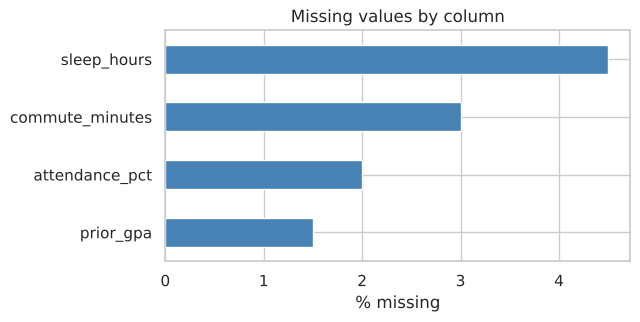

In [6]:
missing_cols = missing[missing.missing > 0].sort_values("missing")
missing_cols["percent"].plot(kind="barh", color="steelblue", figsize=(6, 3))
plt.xlabel("% missing")
plt.title("Missing values by column")
plt.show()

#### Cell: Check duplicates and categories

**What this cell does.** Counts duplicated rows and duplicated student IDs, then lists how many students are in each major.

**The code, line by line:**
- `df.duplicated().sum()` counts rows that are exact copies of an earlier row.
- `df.student_id.duplicated().sum()` counts repeated IDs (the same student entered twice, even if other values differ).
- `df["major"].value_counts()` counts each category, largest first.

**Why it matters.** Duplicates would make some students count twice and bias the results. Category counts show whether every group is large enough to analyze; a category with only a handful of students gives unreliable estimates.

**How to read the output.** There are **0 duplicate rows and 0 duplicate IDs**. Majors are reasonably balanced: Business 143, Engineering 125, Data Science 122, Health 116, Humanities 94. Every group has enough students.

In [7]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate student IDs:", df.student_id.duplicated().sum())
print()
print(df["major"].value_counts())

Duplicate rows: 0
Duplicate student IDs: 0

major
Business        143
Engineering     125
Data Science    122
Health          116
Humanities       94
Name: count, dtype: int64


**What we see:** four columns have gaps (sleep, commute, attendance and GPA), each under 5%. There are no duplicate rows or IDs. We will handle the gaps in Section 4.

### 3.3 The target: performance level

#### Cell: Distribution of the target

**What this cell does.** Counts students in each performance level, shows the percentages, and draws a bar chart.

**The code, line by line:**
- `level_order` fixes the order Low → Medium → High (otherwise pandas sorts alphabetically: High, Low, Medium).
- `value_counts().reindex(level_order)` counts each level in that order.
- `.plot(kind="bar", color=[...])` draws one bar per level; `rot=0` keeps labels horizontal.

**Why it matters.** Class balance affects how to judge a classifier. If one level dominated (say 90% Medium), a model could score 90% accuracy by always guessing Medium while learning nothing.

**How to read the output.** **Low 160 (26.7%), Medium 261 (43.5%), High 179 (29.8%).** The classes are reasonably balanced. The **baseline** a model must beat is 43.5%, the accuracy of always guessing Medium.

                   students  percent
performance_level                   
Low                     160     26.7
Medium                  261     43.5
High                    179     29.8


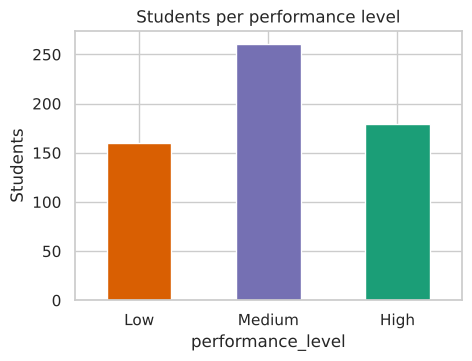

In [8]:
level_order = ["Low", "Medium", "High"]
counts = df["performance_level"].value_counts().reindex(level_order)
print(pd.DataFrame({"students": counts, "percent": (counts / len(df) * 100).round(1)}))
counts.plot(kind="bar", color=["#d95f02", "#7570b3", "#1b9e77"], figsize=(5, 3.5), rot=0)
plt.ylabel("Students"); plt.title("Students per performance level")
plt.show()

The classes are reasonably balanced, so accuracy is a fair first measure. A model that always guessed the largest class (Medium) would be right about 43% of the time: that is the **baseline** to beat.

### 3.4 Predictors by performance level

#### Cell: Define groups of columns

**What this cell does.** Stores the names of the numeric and the 0/1 (binary) predictors in two lists so later cells can loop over them.

**The code, line by line:**
- `numeric_cols`: the six continuous predictors (hours, %, GPA, minutes).
- `binary_cols`: the three yes/no predictors coded 0/1.

**Why it matters.** Writing the lists once avoids typos and makes the notebook easy to reuse: **to adapt the template, change these lists** to your own column names.

**How to read the output.** Nothing is printed.

In [9]:
numeric_cols = ["study_hours_week", "attendance_pct", "prior_gpa", "sleep_hours",
                "work_hours_week", "commute_minutes"]
binary_cols = ["works_part_time", "study_group", "first_generation"]

#### Cell: Distributions of the numeric predictors

**What this cell does.** Draws a histogram with a smooth density curve for each of the six numeric predictors, in a 2 × 3 grid.

**The code, line by line:**
- `plt.subplots(2, 3, figsize=(14, 7))` creates a figure with 6 panels; `axes.flat` lets us loop through them.
- `zip(axes.flat, numeric_cols)` pairs each panel with one column.
- `sns.histplot(..., kde=True)` draws the histogram plus a **kernel density estimate** (the smooth curve).
- `plt.tight_layout()` stops titles and labels from overlapping.

**Why it matters.** Shape matters: skewed variables, outliers and odd spikes can affect a model. Distributions also help you describe the sample in plain words.

**How to read the output.** Attendance, GPA and sleep are roughly symmetric. **Study hours** (skew 0.9) and especially **commute** (skew 1.4) are right-skewed, with long tails of high values. **Work hours** has a big spike at 0 (the 53% of students without a job) and a separate hump around 15–25 hours for those who work. Regression does **not** require predictors to be normally distributed, but this spike comes back in the assumption checks.

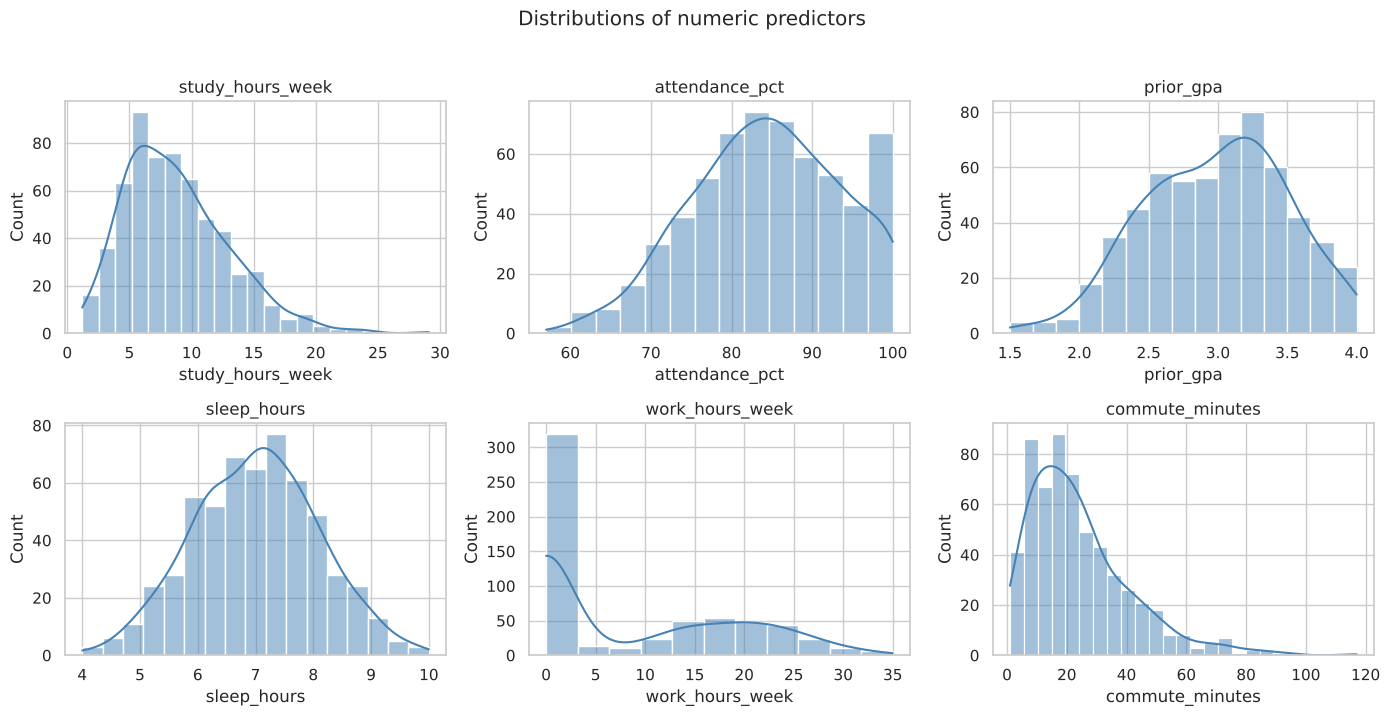

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, numeric_cols):
    sns.histplot(df[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(col)
plt.suptitle("Distributions of numeric predictors", y=1.02)
plt.tight_layout()
plt.show()

#### Cell: Predictors by performance level

**What this cell does.** Draws a boxplot of each numeric predictor for the Low, Medium and High groups.

**The code, line by line:**
- `x="performance_level", y=col` puts the levels on the x-axis and the predictor on the y-axis.
- `order=level_order` keeps Low → Medium → High.
- `hue=..., palette=[...], legend=False` colors each level consistently (orange, purple, green) without an extra legend.

**Why it matters.** This is the classification version of a scatter plot: if a predictor helps separate the levels, its boxes shift up or down from Low to High.

**How to read the output.** Study hours, attendance and prior GPA rise clearly from Low to High; sleep rises slightly. Work hours is higher in the Low group. Commute barely differs. The boxes overlap a lot, which tells us no single variable separates the levels well on its own; combining them is the model's job.

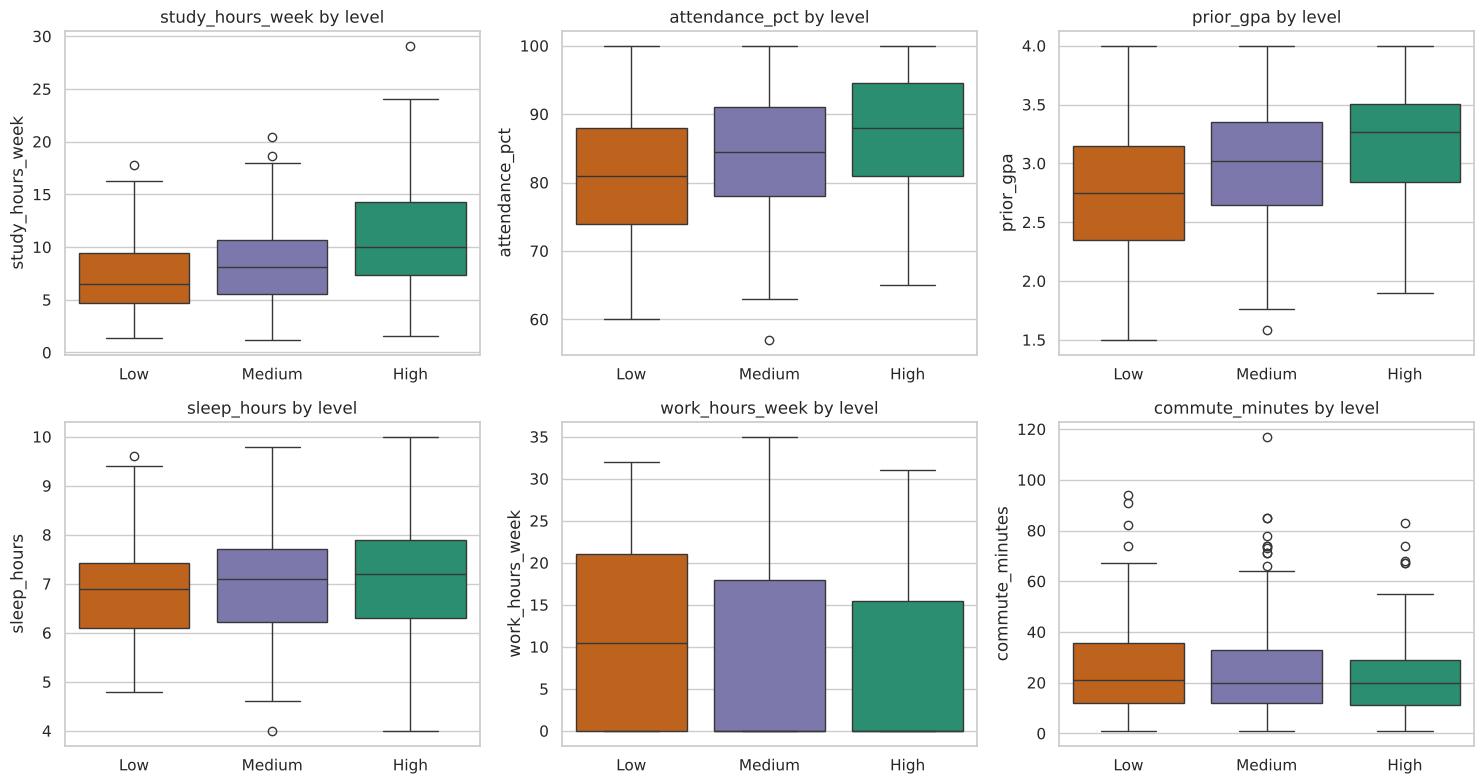

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, numeric_cols):
    sns.boxplot(data=df, x="performance_level", y=col, order=level_order, ax=ax,
                hue="performance_level", hue_order=level_order, palette=["#d95f02", "#7570b3", "#1b9e77"], legend=False)
    ax.set_title(f"{col} by level"); ax.set_xlabel("")
plt.tight_layout()
plt.show()

#### Cell: Average of each predictor by level

**What this cell does.** Calculates the mean of every numeric predictor within each performance level.

**The code, line by line:**
- `groupby("performance_level")[numeric_cols].mean()` averages each predictor within each level.
- `.reindex(level_order)` orders rows Low → Medium → High.

**Why it matters.** Exact numbers to report alongside the boxplots.

**How to read the output.** From Low to High: study hours **7.1 → 8.3 → 10.9**, attendance **80.8% → 84.4% → 87.5%**, prior GPA **2.76 → 3.01 → 3.17**, sleep 6.9 → 7.0 → 7.2, work hours **10.5 → 8.5 → 7.3**, commute 25.3 → 24.9 → 22.1 minutes. Steady, ordered changes like these suggest the predictors will be useful.

In [12]:
df.groupby("performance_level")[numeric_cols].mean().reindex(level_order).round(2)

,study_hours_week,attendance_pct,prior_gpa,sleep_hours,work_hours_week,commute_minutes
performance_level,,,,,,
Low,7.14,80.83,2.76,6.85,10.53,25.30
Medium,8.30,84.43,3.01,7.01,8.53,24.94
High,10.92,87.53,3.17,7.16,7.27,22.06


#### Cell: Performance level by category

**What this cell does.** For each categorical predictor, shows what percentage of students in each group falls into each level.

**The code, line by line:**
- `pd.crosstab(df[col], df["performance_level"], normalize="index")` builds a two-way table where each **row** sums to 100%.
- `* 100` and `.round(1)` convert to percentages with one decimal.

**Why it matters.** Cross-tabulations are the categorical equivalent of comparing means: they show whether the mix of levels differs between groups.

**How to read the output.** **Study group:** 37.5% of members reach High vs 25.5% of non-members, and only 17.1% of members are Low vs 32.0%. **Major:** Data Science has the most High students (41.0%) and the fewest Low (13.9%); Health has the most Low (34.5%). **First-generation** students are slightly less often High (26.6% vs 31.4%) and slightly more often Low (29.7% vs 25.2%), a modest difference.

In [13]:
for col in ["study_group", "first_generation", "major"]:
    tab = pd.crosstab(df[col], df["performance_level"], normalize="index").reindex(columns=level_order)
    print(f"\n% of students in each level, by {col}")
    print((tab * 100).round(1))


% of students in each level, by study_group
performance_level   Low  Medium  High
study_group                          
0                  32.0    42.4  25.5
1                  17.1    45.4  37.5

% of students in each level, by first_generation
performance_level   Low  Medium  High
first_generation                     
0                  25.2    43.4  31.4
1                  29.7    43.8  26.6

% of students in each level, by major
performance_level   Low  Medium  High
major                                
Business           31.5    45.5  23.1
Data Science       13.9    45.1  41.0
Engineering        30.4    44.0  25.6
Health             34.5    39.7  25.9
Humanities         21.3    42.6  36.2


#### Cell: Correlation among predictors

**What this cell does.** Computes and plots correlations between the predictors (the target is categorical, so it is not included).

**The code, line by line:**
- `.corr()` gives Pearson correlations from −1 to +1; `sns.heatmap` colors them (red positive, blue negative).

**Why it matters.** Here the goal is to spot predictors that duplicate each other (multicollinearity), which makes coefficients unstable.

**How to read the output.** Almost all correlations are near 0. The exception is **`works_part_time` and `work_hours_week` (r = 0.90)**: they measure the same thing, so we drop `works_part_time` in Section 4.

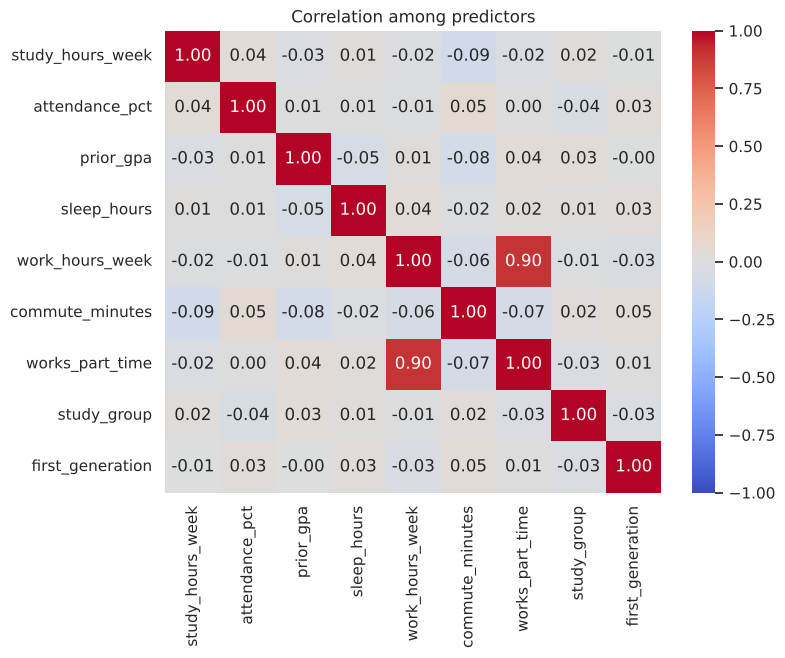

In [14]:
corr = df[numeric_cols + binary_cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation among predictors")
plt.show()

**EDA takeaways** (check these against your own output):
- Students in the High level study more, attend more, sleep a bit more and had higher prior GPAs.
- Low-level students work more hours on average.
- A larger share of study-group members reach High.
- `works_part_time` and `work_hours_week` are strongly correlated, because they measure the same thing.

## 4. Prepare the data

Decisions:

1. **Drop `student_id`** — it is a label, not a predictor.
2. **Drop the other target.** `final_exam_score` is an outcome, not a cause; using it as a predictor would leak the answer.
3. **Drop `works_part_time`.** It carries the same information as `work_hours_week` (0 hours = no job), and including both makes the coefficients unstable.
4. **Split before filling gaps.** 80% of students train the model; 20% are held out to test it.
5. **Fill missing values with the median** of the training set. With under 5% missing per column, median imputation is simple and reasonable. Alternative: drop rows with missing values (`dropna()`), which would lose about 10% of the students.
6. **Code the target as numbers.** statsmodels needs the outcome as integers: **Low = 0** (the reference level), Medium = 1, High = 2.

#### Cell: Split, fill missing values and code the target

**What this cell does.** Splits the data 80/20 keeping the same mix of levels in both parts, fills missing values with training medians, and converts the text target to numbers.

**The code, line by line:**
- `stratify=df["performance_level"]` makes the training and test sets have the same percentage of Low, Medium and High students. Always stratify for classification, or a random split could leave one level underrepresented in the test set.
- `random_state=42` fixes the random split so results are reproducible.
- `medians = train[numeric_cols].median()` and `.fillna(medians)` fill gaps using the **training** medians only (to avoid data leakage).
- `level_codes = {"Low": 0, "Medium": 1, "High": 2}` and `.map(level_codes)` create `level_code`. statsmodels' `mnlogit` needs integer codes; text labels would raise an error.

**Why it matters.** **Low = 0 is the reference level**: every coefficient will compare Medium with Low, or High with Low. Choosing Low as the reference makes the results read naturally as "what moves a student up from Low."

**How to read the output.** Training rows **480** (Low 128, Medium 209, High 143), test rows **120**, no missing values left. The coding dictionary is printed as a reminder.

In [15]:
numeric_cols = ["study_hours_week", "attendance_pct", "prior_gpa", "sleep_hours",
                "work_hours_week", "commute_minutes"]
binary_cols = ["works_part_time", "study_group", "first_generation"]

# Features and the two possible targets
features = ["major"] + numeric_cols + ["study_group", "first_generation"]

train, test = train_test_split(df, test_size=0.2, random_state=42, stratify=df["performance_level"])

# Fill missing numeric values with the TRAINING median (so the test set stays unseen)
medians = train[numeric_cols].median()
train = train.copy(); test = test.copy()
train[numeric_cols] = train[numeric_cols].fillna(medians)
test[numeric_cols] = test[numeric_cols].fillna(medians)

print("Training rows:", len(train), "| Test rows:", len(test))
print("Missing values left:", train[features].isna().sum().sum() + test[features].isna().sum().sum())
print("\nMedians used to fill gaps:\n", medians[["attendance_pct", "prior_gpa", "sleep_hours", "commute_minutes"]])

level_codes = {"Low": 0, "Medium": 1, "High": 2}
train["level_code"] = train["performance_level"].map(level_codes)
test["level_code"] = test["performance_level"].map(level_codes)
print("\nTarget coding:", level_codes)
print(train["level_code"].value_counts().sort_index())

Training rows: 480 | Test rows: 120
Missing values left: 0

Medians used to fill gaps:
 attendance_pct     84.00
prior_gpa           3.02
sleep_hours         7.00
commute_minutes    21.00
dtype: float64

Target coding: {'Low': 0, 'Medium': 1, 'High': 2}
level_code
0    128
1    209
2    143
Name: count, dtype: int64


## 5. Fit the model

`smf.mnlogit` fits one set of coefficients for **Medium vs Low** and another for **High vs Low**. `C(major)` creates dummy variables with Business as the reference major. Stratifying the split kept the same mix of levels in the training and test sets.

#### Cell: Fit the multinomial logistic regression

**What this cell does.** Fits a multinomial logistic regression and prints the results.

**The code, line by line:**
- The formula has the same predictors as the linear model, but the outcome is `level_code` (0, 1, 2).
- `C(major)` creates dummy variables with Business as the reference major.
- `smf.mnlogit(...)` estimates **two equations at once**: the log-odds of Medium vs Low, and of High vs Low. (With *K* levels there are *K* − 1 equations.)
- `.fit(maxiter=200, disp=0)` estimates the coefficients by **maximum likelihood**, an iterative search. `maxiter=200` allows up to 200 steps; `disp=0` hides the progress messages.

**Why it matters.** Each equation says how the predictors change the chance of being in that level **instead of Low**, holding the other predictors constant.

**How to read the output.** Top block: **converged: True** (the estimation finished properly), **Pseudo R-squared = 0.22** (McFadden's measure; 0.2–0.4 indicates a good fit for logistic models and is not comparable to linear R²), and **LLR p-value ≈ 5 × 10⁻³⁵** (the model is far better than one with no predictors).

The two blocks are labeled **level_code=1** (Medium vs Low) and **level_code=2** (High vs Low). In each, `coef` is the change in **log-odds**. For example, study hours has 0.14 for Medium and 0.32 for High: more study raises the odds of both, but much more for High. Positive = more likely than Low; negative = less likely.

In [16]:
formula = ("level_code ~ study_hours_week + attendance_pct + prior_gpa + sleep_hours"
           " + work_hours_week + commute_minutes + study_group + first_generation + C(major)")
model = smf.mnlogit(formula, data=train).fit(maxiter=200, disp=0)
print(model.summary())

                          MNLogit Regression Results                          
Dep. Variable:             level_code   No. Observations:                  480
Model:                        MNLogit   Df Residuals:                      454
Method:                           MLE   Df Model:                           24
Date:                Fri, 30 Oct 2026   Pseudo R-squ.:                  0.2201
Time:                        18:30:08   Log-Likelihood:                -402.50
converged:                       True   LL-Null:                       -516.12
Covariance Type:            nonrobust   LLR p-value:                 5.103e-35
            level_code=1       coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept                  -11.9329      1.937     -6.161      0.000     -15.729      -8.137
C(major)[T.Data Science]     1.0907      0.439      2.487      0.013       0.231       1.

### How to read the summary

- The output has two blocks: **level_code=1** (Medium vs Low) and **level_code=2** (High vs Low).
- **coef** is the change in the *log-odds* of being in that level instead of Low, for a one-unit increase in the predictor, holding the others constant. Positive = more likely than Low.
- **P>|z|** below 0.05 means the effect is statistically significant.
- **Pseudo R-squared** (McFadden) is not the same as linear R²; values of 0.2–0.4 indicate a good fit.

Log-odds are hard to read, so we convert them to **odds ratios** with `exp(coef)`.

#### Cell: Odds ratios

**What this cell does.** Converts the log-odds coefficients into odds ratios and shows them next to their p-values.

**The code, line by line:**
- `model.params` has one column per equation; we rename them "Medium vs Low" and "High vs Low".
- `np.exp(params)` turns each coefficient into an **odds ratio** (e raised to the coefficient).
- `pd.concat({...}, axis=1)` puts the odds ratios and p-values side by side.

**Why it matters.** Log-odds are hard to explain; odds ratios are not. An odds ratio says by how much the odds are **multiplied** for a one-unit increase.

**How to read the output.** **Study hours:** 1.15 (Medium vs Low) and **1.38** (High vs Low): each extra weekly hour multiplies the odds of High instead of Low by 1.38, a 38% increase. **Prior GPA:** 3.76 and **11.6** per full GPA point (a big unit; half a point multiplies the odds by about 3.4). **Study group:** 2.37 and **4.39**. **Attendance:** 1.07 and 1.13 per percentage point. **Work hours:** 0.96 per hour for High vs Low (each hour lowers the odds by about 4%). Values below 1 lower the odds; values near 1 with large p-values (commute, first-generation) show no clear effect.

In [17]:
params = model.params.copy()
params.columns = ["Medium vs Low", "High vs Low"]
pvals = model.pvalues.copy(); pvals.columns = params.columns
odds = np.exp(params).round(3)
table = pd.concat({"odds ratio": odds, "p-value": pvals.round(4)}, axis=1).drop("Intercept")
table

odds ratio                   p-value            
                         Medium vs Low High vs Low Medium vs Low High vs Low
C(major)[T.Data Science]         2.976       7.826        0.0129      0.0001
C(major)[T.Engineering]          0.864       0.760        0.6820      0.5616
C(major)[T.Health]               0.648       0.898        0.2266      0.8220
C(major)[T.Humanities]           1.370       3.034        0.4537      0.0323
study_hours_week                 1.154       1.379        0.0002      0.0000
attendance_pct                   1.073       1.132        0.0000      0.0000
prior_gpa                        3.759      11.599        0.0000      0.0000
sleep_hours                      1.292       1.742        0.0417      0.0003
work_hours_week                  0.982       0.964        0.1478      0.0181
commute_minutes                  0.995       0.990        0.4873      0.2858
study_group                      2.374       4.389        0.0037      0.0000
first_generation                 0.717       0.605        0.2048      0.1273

**Reading odds ratios:** 1 = no effect; above 1 = higher odds of that level (instead of Low); below 1 = lower odds.
Example: an odds ratio of 1.30 for `study_hours_week` in the High vs Low column means each extra weekly study hour multiplies the odds of being High rather than Low by 1.30 (a 30% increase), holding the other variables constant.

## 6. Which variables matter most?

Two complementary views:
1. **Standardized coefficients:** refit with numeric predictors in standard-deviation units, so effects are on the same scale.
2. **Likelihood-ratio tests:** drop one variable at a time and measure how much worse the model fits. A bigger drop (larger chi-square) means a more important variable. This gives one number per variable across both comparisons.

#### Cell: Standardized coefficients

**What this cell does.** Rescales the numeric predictors to standard-deviation units, refits the model, and ranks variables by their average effect across the two equations.

**The code, line by line:**
- `(train[col] - mean) / std` converts each numeric predictor to z-scores (0 = average, 1 = one SD above).
- The refit coefficients mean *change in log-odds for a 1-SD increase*.
- `std.abs().mean(axis=1)` averages the absolute effect across the two equations to give one ranking number.

**Why it matters.** Puts numeric predictors measured in hours, %, GPA points and minutes on the same scale. The 0/1 variables and majors are not rescaled, so their values are full yes-vs-no differences and tend to look large; compare them with caution.

**How to read the output.** Among numeric predictors, study hours, prior GPA and attendance have the largest standardized effects (each about 1.1–1.3 log-odds per SD for High vs Low), then sleep, work hours and commute. Data Science and study group top the list partly because they are 0/1 variables (see the note above).

In [18]:
# Standardize numeric predictors (mean 0, SD 1) so coefficients are comparable:
# each coefficient = change in the outcome for a 1-standard-deviation increase.
train_z = train.copy()
for col in numeric_cols:
    train_z[col] = (train[col] - train[col].mean()) / train[col].std()
model_z = smf.mnlogit(formula, data=train_z).fit(maxiter=200, disp=0)
std = model_z.params.copy(); std.columns = ["Medium vs Low", "High vs Low"]
std = std.drop("Intercept")
std["avg_abs_effect"] = std.abs().mean(axis=1)
std.sort_values("avg_abs_effect", ascending=False).round(3)

,Medium vs Low,High vs Low,avg_abs_effect
C(major)[T.Data Science],1.091,2.057,1.574
study_group,0.865,1.479,1.172
study_hours_week,0.600,1.341,0.971
prior_gpa,0.669,1.238,0.954
attendance_pct,0.635,1.121,0.878
C(major)[T.Humanities],0.315,1.110,0.712
sleep_hours,0.270,0.585,0.427
first_generation,-0.333,-0.503,0.418
work_hours_week,-0.183,-0.374,0.278
C(major)[T.Health],-0.433,-0.107,0.270


#### Cell: Likelihood-ratio tests for importance

**What this cell does.** Removes one variable at a time, refits the model, and measures how much worse it fits.

**The code, line by line:**
- `formula.replace(f" + {term}", "")` builds the formula without one variable.
- `model.llf` is the **log-likelihood**, a measure of fit (higher is better).
- **LR χ² = 2 × (log-likelihood of full model − log-likelihood without the variable).** The bigger it is, the more the model relies on that variable.
- `df` is the number of coefficients removed: 2 for a numeric or 0/1 variable (one per equation), 8 for major (4 dummies × 2 equations).
- `stats.chi2.sf(lr, df)` converts the statistic into a p-value.

**Why it matters.** Unlike standardized coefficients, this gives **one number per variable** that combines both equations and treats numeric, binary and categorical variables fairly. It is the best single guide to importance in a multinomial model.

**How to read the output.** Ranking: **study hours (χ² = 70.1), prior GPA (58.9), attendance (49.2), major (33.4), study group (18.7), sleep (14.4)**, all p < 0.001. Work hours is borderline (5.7, p = 0.058). First-generation (2.5) and commute (1.2) do not improve the model.

In [19]:
from scipy import stats
terms = ["study_hours_week", "attendance_pct", "prior_gpa", "sleep_hours", "work_hours_week",
         "commute_minutes", "study_group", "first_generation", "C(major)"]
rows = []
for term in terms:
    reduced = formula.replace(f" + {term}", "").replace(f"~ {term} + ", "~ ")
    m0 = smf.mnlogit(reduced, data=train).fit(maxiter=200, disp=0)
    lr = 2 * (model.llf - m0.llf)
    df_diff = model.df_model - m0.df_model
    rows.append({"variable": term, "LR_chi2": lr, "df": int(df_diff), "p_value": stats.chi2.sf(lr, df_diff)})
lr_table = pd.DataFrame(rows).sort_values("LR_chi2", ascending=False).reset_index(drop=True)
lr_table.round(4)

,variable,LR_chi2,df,p_value
0,study_hours_week,70.1363,2,0.0000
1,prior_gpa,58.9372,2,0.0000
2,attendance_pct,49.1667,2,0.0000
3,C(major),33.4107,8,0.0001
4,study_group,18.7368,2,0.0001
5,sleep_hours,14.3699,2,0.0008
6,work_hours_week,5.6855,2,0.0583
7,first_generation,2.4913,2,0.2878
8,commute_minutes,1.1680,2,0.5577


#### Cell: Importance chart

**What this cell does.** Draws the likelihood-ratio χ² for each variable as a horizontal bar, orange if significant at 5%.

**The code, line by line:**
- Bars are sorted so the most important variable is at the top.

**Why it matters.** A visual summary of which variables matter most.

**How to read the output.** Study hours, prior GPA and attendance stand out; commute and first-generation are gray.

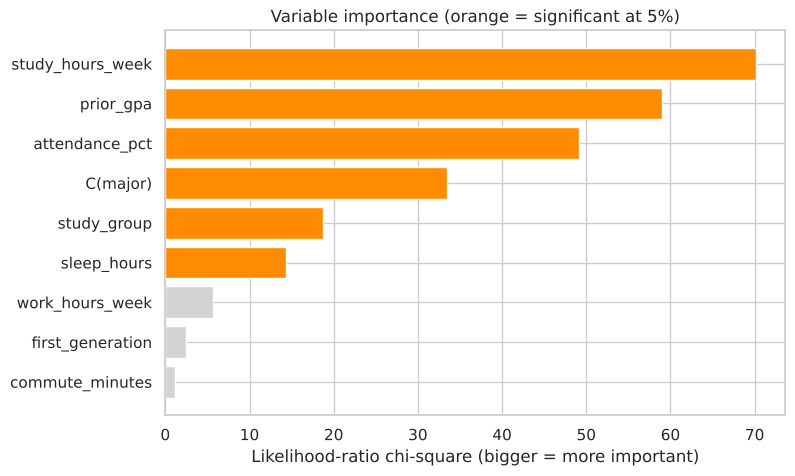

In [20]:
lt = lr_table.sort_values("LR_chi2")
colors = ["darkorange" if p < 0.05 else "lightgray" for p in lt.p_value]
plt.figure(figsize=(8, 5))
plt.barh(lt.variable, lt.LR_chi2, color=colors)
plt.xlabel("Likelihood-ratio chi-square (bigger = more important)")
plt.title("Variable importance (orange = significant at 5%)")
plt.show()

## 7. Check the model assumptions

Multinomial logistic regression has different assumptions from linear regression. It does **not** require normal residuals, equal variance or a linear relationship between the predictors and the outcome itself. It does require:

| # | Assumption | What it means | How we check |
| --- | --- | --- | --- |
| 1 | Categorical outcome | Each student is in exactly one of 3 unordered or ordered groups | Value counts |
| 2 | Independence | Each row is a different student | Study design |
| 3 | Adequate sample size | Enough students in each level for the number of coefficients | Cases per parameter |
| 4 | No multicollinearity | Predictors are not near-copies of each other | VIF |
| 5 | Linearity in the log-odds | Each numeric predictor has a straight-line relationship with the log-odds | Box-Tidwell test; binned log-odds plots |
| 6 | No overly influential points | No single student drives the results | Cook's distance from the two binary comparisons |
| 7 | No complete separation | No predictor perfectly splits the levels | Standard errors, predicted probabilities, convergence |
| 8 | Independence of irrelevant alternatives (IIA) | The odds between two levels do not depend on the third level | Hausman-McFadden test |

For each formal test, the **null hypothesis is that the assumption holds**: a p-value above 0.05 means no evidence of a problem.

### 7.1 Categorical outcome and 7.2 independence

#### Cell: Check the outcome and independence

**What this cell does.** Confirms that every student has exactly one level and appears only once.

**The code, line by line:**
- `value_counts()` shows the size of each level. `.notna().all()` checks that no level is missing. `.is_unique` checks that no student ID repeats.

**Why it matters.** A multinomial model requires one outcome category per observation and independent observations.

**How to read the output.** See the paragraph below the output.

In [21]:
print(train["performance_level"].value_counts().reindex(["Low", "Medium", "High"]))
print("\nEvery student has exactly one level:", train["performance_level"].notna().all())
print("Each student appears once:", train["student_id"].is_unique)

performance_level
Low       128
Medium    209
High      143
Name: count, dtype: int64

Every student has exactly one level: True
Each student appears once: True


**Interpretation.** The outcome has three mutually exclusive levels, and every student belongs to exactly one, so a multinomial model is appropriate. Each row is a different student measured once, so observations are independent by design. **Both assumptions are met.** One note for later: the three levels have a natural order (Low < Medium < High). Multinomial regression ignores that order, which is allowed, but it is relevant to the IIA check in 7.8.

### 7.3 Adequate sample size

#### Cell: Check the sample size

**What this cell does.** Compares the size of the smallest level with the number of coefficients estimated per equation.

**The code, line by line:**
- `model.model.exog.shape[1]` is the number of columns in the predictor matrix (including the intercept), so subtracting 1 gives the number of predictor coefficients per equation.
- The ratio smallest level ÷ coefficients is compared with the rule of thumb of 10.

**Why it matters.** Too few cases per coefficient gives unstable, biased estimates and inflated odds ratios.

**How to read the output.** See the paragraph below the output.

In [22]:
n_params = model.model.exog.shape[1] - 1          # coefficients per equation, excluding the intercept
smallest = train["level_code"].value_counts().min()
print(f"Predictor coefficients per equation: {n_params}")
print(f"Smallest level in the training set:  {smallest} students")
print(f"Cases per coefficient in the smallest level: {smallest / n_params:.1f}   (rule of thumb: at least 10)")

Predictor coefficients per equation: 12
Smallest level in the training set:  128 students
Cases per coefficient in the smallest level: 10.7   (rule of thumb: at least 10)


**Interpretation.** A common rule of thumb asks for at least 10 cases in the smallest outcome group for each coefficient estimated. The smallest level (Low) has 128 training students and the model estimates 12 coefficients per equation, giving about 10.7 cases per coefficient. **The sample size is adequate, but only just.** Adding many more predictors or interactions would make estimates unstable; with a smaller dataset you would need fewer predictors.

### 7.4 Multicollinearity

#### Cell: Multicollinearity: VIF

**What this cell does.** Calculates the variance inflation factor of each predictor.

**The code, line by line:**
- `variance_inflation_factor(X, i)` measures how well predictor *i* is explained by the other predictors (VIF = 1 ÷ (1 − R²)). It depends only on the predictors, so it works the same way as for linear regression.

**Why it matters.** Overlapping predictors make odds ratios unstable and hard to interpret.

**How to read the output.** Below 5 is fine; above 10 is serious.

In [23]:
X = model.model.exog
vif = pd.DataFrame({"variable": model.model.exog_names,
                    "VIF": [variance_inflation_factor(X, i) for i in range(X.shape[1])]})
vif = vif[vif.variable != "Intercept"].round(2)
print("Rule of thumb: VIF above 5 is a concern, above 10 is serious")
vif

Rule of thumb: VIF above 5 is a concern, above 10 is serious


,variable,VIF
1,C(major)[T.Data Science],1.56
2,C(major)[T.Engineering],1.58
3,C(major)[T.Health],1.50
4,C(major)[T.Humanities],1.43
5,study_hours_week,1.03
6,attendance_pct,1.01
7,prior_gpa,1.02
8,sleep_hours,1.01
9,work_hours_week,1.02
10,commute_minutes,1.04


**Interpretation.** Multicollinearity depends only on the predictors, so it is checked the same way as in linear regression. All VIFs are between 1.0 and 1.6, well below 5. **There is no multicollinearity problem**, so each odds ratio can be read as the effect of that variable holding the others constant. Dropping `works_part_time` in Section 4 helped here, since it duplicates `work_hours_week`.

### 7.5 Linearity in the log-odds

The model assumes that each numeric predictor changes the **log-odds** by the same amount at every value (for example, going from 2 to 3 study hours has the same effect as going from 20 to 21). The **Box-Tidwell test** adds a term `x × ln(x)` for one predictor at a time; if that term improves the model, the relationship is curved. Logs need positive values, so `work_hours_week` (which is 0 for students without a job) is shifted by 1 first.

#### Cell: Linearity in the log-odds: Box-Tidwell test

**What this cell does.** For each numeric predictor, adds an extra term x × ln(x) to the model and tests whether it improves the fit.

**The code, line by line:**
- `shift = 1 if (train[col] <= 0).any() else 0`: logs only work for positive numbers, so columns containing 0 (work hours) are shifted up by 1.
- `tmp["bt_term"] = (x + shift) * np.log(x + shift)` creates the Box-Tidwell term.
- The likelihood-ratio test compares the model with and without that term (2 degrees of freedom, one per equation).
- The **Bonferroni threshold** 0.05 ÷ 6 adjusts for running six tests at once, which raises the chance of a false alarm.

**Why it matters.** Logistic regression assumes each numeric predictor has a straight-line effect on the **log-odds** (not on the probability, which is S-shaped). A significant Box-Tidwell term means the effect is curved.

**How to read the output.** Look for p-values above 0.05 (or above the Bonferroni threshold for a stricter standard).

In [24]:
rows = []
for col in numeric_cols:
    shift = 1 if (train[col] <= 0).any() else 0
    tmp = train.copy()
    tmp["bt_term"] = (tmp[col] + shift) * np.log(tmp[col] + shift)
    m_bt = smf.mnlogit(formula + " + bt_term", data=tmp).fit(maxiter=300, disp=0)
    lr = 2 * (m_bt.llf - model.llf)
    rows.append({"predictor": col, "shifted by": shift, "LR chi2": round(lr, 2),
                 "p-value": round(stats.chi2.sf(lr, 2), 3)})
bt = pd.DataFrame(rows)
print(f"Bonferroni-corrected threshold for {len(bt)} tests: {0.05/len(bt):.4f}")
bt

Bonferroni-corrected threshold for 6 tests: 0.0083


,predictor,shifted by,LR chi2,p-value
0,study_hours_week,0,1.49,0.474
1,attendance_pct,0,0.39,0.823
2,prior_gpa,0,2.25,0.325
3,sleep_hours,0,4.15,0.126
4,work_hours_week,1,6.71,0.035
5,commute_minutes,0,0.03,0.983


#### Cell: Linearity in the log-odds: binned plots

**What this cell does.** For the High vs Low comparison, groups students into six bins of each predictor and plots the observed log-odds of being High in each bin.

**The code, line by line:**
- `hl` keeps only Low and High students; `is_high` is 1 for High.
- `pd.qcut(..., 6)` splits each predictor into six equal-sized groups (about 45 students each); `.rank(method="first")` breaks ties so the split works even with many repeated values.
- The share of High students in each bin is converted to **log-odds**: ln(p ÷ (1 − p)). `.clip(0.02, 0.98)` avoids log(0).

**Why it matters.** A visual companion to the Box-Tidwell test: if the relationship is linear in the log-odds, the points should follow a roughly straight line.

**How to read the output.** Each point is based on few students and does not adjust for the other variables, so expect some zigzag. Look for the overall direction and any clear bend.

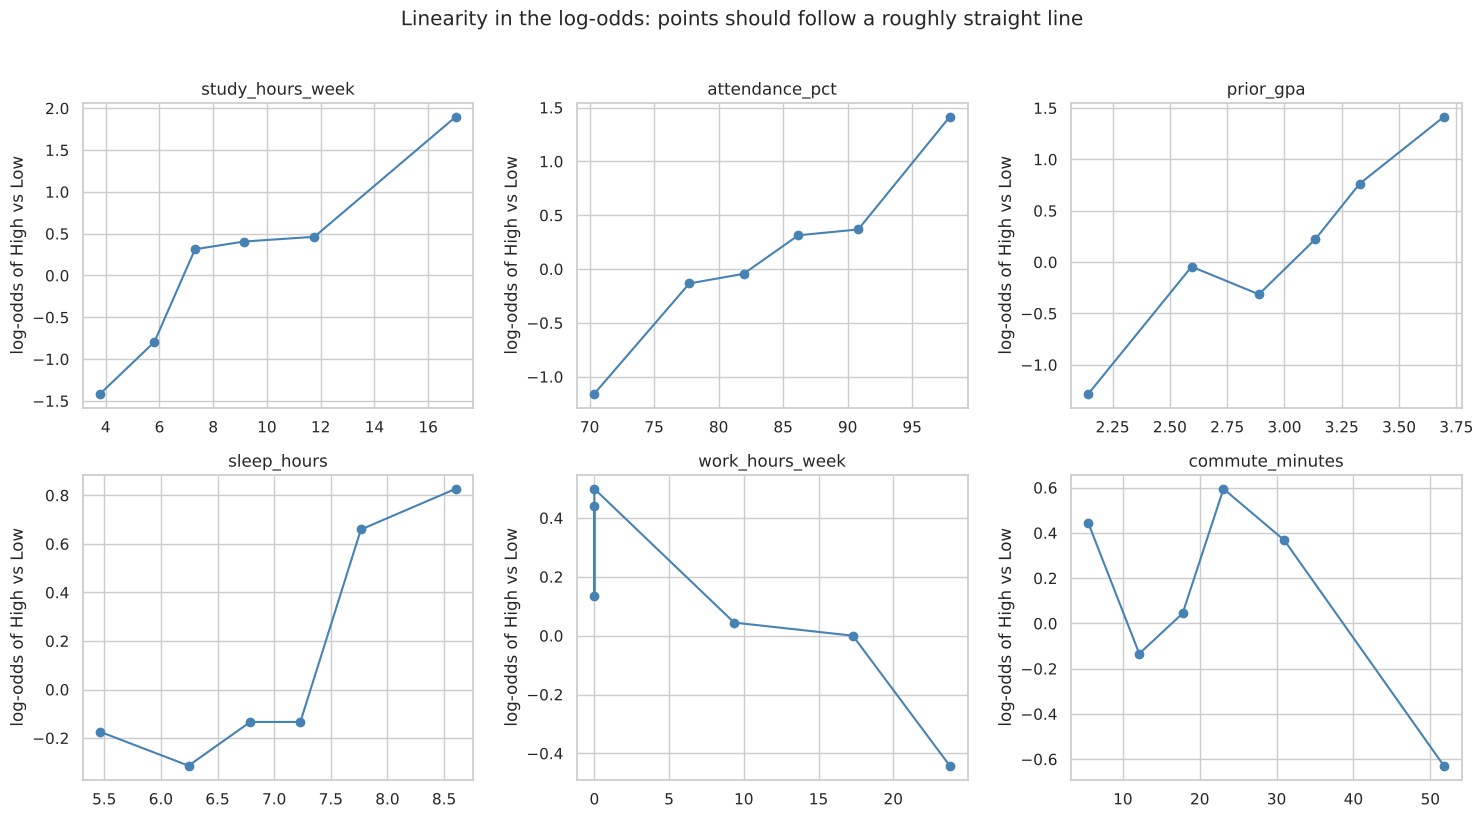

In [25]:
# Visual check: observed log-odds of High vs Low across groups of each predictor
hl = train[train.level_code != 1].copy()
hl["is_high"] = (hl.level_code == 2).astype(int)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, numeric_cols):
    bins = pd.qcut(hl[col].rank(method="first"), 6, labels=False)
    g = hl.groupby(bins).agg(x=(col, "mean"), p=("is_high", "mean"))
    g["p"] = g["p"].clip(0.02, 0.98)
    ax.plot(g.x, np.log(g.p / (1 - g.p)), "o-", color="steelblue")
    ax.set_title(f"{col}"); ax.set_ylabel("log-odds of High vs Low")
plt.suptitle("Linearity in the log-odds: points should follow a roughly straight line", y=1.02)
plt.tight_layout()
plt.show()

**Interpretation.** For five of the six numeric predictors the Box-Tidwell terms are clearly not significant (p from 0.13 to 0.98), so the linearity assumption holds for study hours, attendance, prior GPA, sleep and commute. The binned plots are noisy, because each point is based on only about 45 students and does not adjust for the other variables, but study hours, attendance and prior GPA rise in a roughly straight line, and sleep and commute bounce around without a consistent curve. **Work hours is the exception** (p = 0.035): its relationship with the log-odds appears curved. The likely reason is the large spike at 0, visible in its plot as several groups stacked at zero hours: students without a job are a different group from those who work a few hours. With six tests, the Bonferroni-corrected threshold is 0.008, so this result is not significant after correcting for multiple testing; it is a mild warning rather than a clear violation. A simple fix to try is adding `works_part_time` back alongside `work_hours_week`, or grouping work hours into bands (0, 1–15, 16+).

### 7.6 Influential points

statsmodels does not provide influence measures for multinomial models directly, so we fit the two comparisons the model makes (**Medium vs Low** and **High vs Low**) as separate binary logistic regressions and compute Cook's distance for each.

#### Cell: Influential points

**What this cell does.** Fits the two comparisons (Medium vs Low, High vs Low) as separate binary logistic regressions and computes Cook's distance for each student.

**The code, line by line:**
- `sub` keeps the students in the two levels being compared; `y_bin` is 1 for the higher level.
- `smf.glm(..., family=sm.families.Binomial())` fits a logistic regression as a generalized linear model, which provides influence measures.
- `get_influence().cooks_distance[0]` gives Cook's distance: how much the coefficients would change if that student were removed. Above 4/n is a cautious flag; above 1 is serious.

**Why it matters.** A handful of unusual students should not drive the conclusions. statsmodels has no influence measures for `mnlogit` itself, and the two binary models closely approximate its two equations.

**How to read the output.** Look at the largest value and the height of the tallest spikes relative to 1.

Medium vs Low: n = 337, largest Cook's D = 0.034, above 4/n = 10, above 1 = 0
High vs Low: n = 271, largest Cook's D = 0.058, above 4/n = 26, above 1 = 0


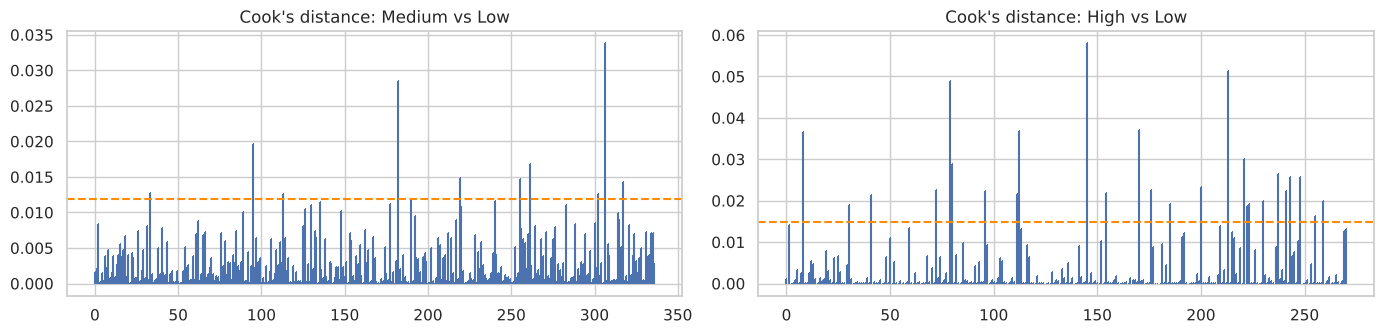

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
for ax, (a, label) in zip(axes, [(1, "Medium vs Low"), (2, "High vs Low")]):
    sub = train[train.level_code.isin([a, 0])].copy()
    sub["y_bin"] = (sub.level_code == a).astype(int)
    glm = smf.glm(formula.replace("level_code ~", "y_bin ~"), data=sub, family=sm.families.Binomial()).fit()
    cd = glm.get_influence().cooks_distance[0]
    print(f"{label}: n = {len(sub)}, largest Cook's D = {cd.max():.3f}, "
          f"above 4/n = {(cd > 4/len(sub)).sum()}, above 1 = {(cd > 1).sum()}")
    ax.stem(range(len(cd)), cd, markerfmt=",", basefmt=" ")
    ax.axhline(4/len(sub), color="darkorange", linestyle="--")
    ax.set_title(f"Cook's distance: {label}")
plt.tight_layout()
plt.show()

**Interpretation.** In both comparisons the largest Cook's distance is small (0.034 for Medium vs Low and 0.058 for High vs Low), far below the threshold of 1 for a seriously influential point. Some students exceed the cautious 4/n guideline (10 and 26), which is normal in samples of this size and reflects students whose outcome was less expected given their profile. **No single student drives the results.**

### 7.7 Complete separation

#### Cell: Complete separation

**What this cell does.** Checks for the warning signs of separation: failure to converge, very large standard errors, and predicted probabilities of 0 or 1.

**The code, line by line:**
- `model.mle_retvals["converged"]` reports whether the estimation finished properly.
- `model.bse` holds the standard errors; `.max().max()` finds the largest across both equations.
- `model.predict(train)` gives each student's predicted probability of each level.

**Why it matters.** If a predictor perfectly separates the levels (e.g., every student above some value is High), maximum likelihood cannot settle on finite coefficients: they and their standard errors grow without limit, and p-values become meaningless.

**How to read the output.** See the paragraph below the output.

In [27]:
probs_train = model.predict(train).values
print("Model converged:", model.mle_retvals["converged"])
print(f"Largest standard error: {model.bse.max().max():.2f}")
print(f"Highest predicted probability for any student: {probs_train.max():.3f}")
print(f"Students predicted with probability > 0.99: {(probs_train.max(axis=1) > 0.99).sum()}")

Model converged: True
Largest standard error: 2.62
Highest predicted probability for any student: 0.986
Students predicted with probability > 0.99: 0


**Interpretation.** Complete separation happens when a predictor (or combination) perfectly sorts students into levels; the model then cannot estimate finite coefficients, and the warning signs are failure to converge, huge standard errors and predicted probabilities of exactly 0 or 1. Here the model converged, the largest standard error is 2.6 (on the intercept, which sits far from typical values), and no student is predicted with more than 99% certainty. **There is no separation problem.**

### 7.8 Independence of irrelevant alternatives (IIA)

IIA means the odds of High vs Low should be the same whether or not Medium is an option. The **Hausman-McFadden test** refits a comparison after removing one level and checks whether the coefficients change more than chance would explain.

#### Cell: Independence of irrelevant alternatives (IIA)

**What this cell does.** Runs the Hausman-McFadden test twice: once removing Medium and refitting High vs Low, once removing High and refitting Medium vs Low, then checks whether the coefficients changed.

**The code, line by line:**
- `restricted` is a binary logistic regression on the two remaining levels.
- `b_full` and `V_full`: the coefficients and their covariance matrix for that comparison in the full multinomial model. `b_r` and `V_r`: the same from the restricted model.
- The test statistic is **d′ (V_r − V_full)⁻¹ d**, where d = the difference in coefficients; `np.linalg.pinv` computes a stable inverse. Under IIA it follows a χ² distribution with as many degrees of freedom as coefficients compared (12).

**Why it matters.** IIA says the odds between two levels do not depend on whether a third level exists. Multinomial logistic regression builds this in, so if it fails, the comparisons may be distorted. It is mostly a concern when levels are close substitutes (the classic example: adding a "blue bus" option should not change the odds of car vs red bus).

**How to read the output.** A p-value above 0.05 means no evidence against IIA. These tests can give unstable or conflicting results in moderate samples, so read them as a flag, not a verdict.

In [28]:
cov = model.cov_params()
def hausman_iia(drop_code, keep_code, label):
    sub = train[train.level_code != drop_code].copy()
    sub["y_bin"] = (sub.level_code == keep_code).astype(int)
    restricted = smf.logit(formula.replace("level_code ~", "y_bin ~"), data=sub).fit(disp=0)
    names = [n for n in restricted.params.index if n != "Intercept"]
    col = {1: 0, 2: 1}[keep_code]
    b_full = model.params.iloc[:, col].loc[names]
    idx = [(str(keep_code), n) for n in names]
    V_full = cov.loc[idx, idx].values
    b_r, V_r = restricted.params.loc[names], restricted.cov_params().loc[names, names].values
    d = (b_r - b_full).values
    stat = float(d @ np.linalg.pinv(V_r - V_full) @ d)
    return {"test": label, "chi2": round(stat, 2), "df": len(names),
            "p-value": round(stats.chi2.sf(abs(stat), len(names)), 3)}

pd.DataFrame([hausman_iia(1, 2, "Remove Medium: is High vs Low unchanged?"),
              hausman_iia(2, 1, "Remove High: is Medium vs Low unchanged?")])

,test,chi2,df,p-value
0,Remove Medium: is High vs Low unchanged?,24.51,12,0.017
1,Remove High: is Medium vs Low unchanged?,1.43,12,1.000


**Interpretation.** The two tests disagree. Removing High leaves the Medium vs Low coefficients essentially unchanged (p = 1.00), but removing Medium does change the High vs Low comparison (χ² = 24.5, p = 0.017), which suggests IIA may not hold for that pair. This makes sense here: the levels are **ordered**, so Medium is not an "irrelevant" alternative; it sits between Low and High, and the students closest to the Low/High boundary are exactly the Medium ones. Statisticians also caution that Hausman tests are unstable in samples of this size and often give conflicting answers, so this result is best read as a flag rather than a verdict. **The practical lesson:** because the outcome is ordered, an **ordinal logistic regression** (statsmodels `OrderedModel`), which uses the ordering and does not rely on IIA, is a natural model to compare with this one.

### 7.9 Summary of the assumption checks

#### Cell: Summary table of assumption checks

**What this cell does.** Collects the evidence and verdict for every assumption into one table.

**The code, line by line:**
- Values such as the cases per coefficient, maximum VIF, Box-Tidwell p-value and largest standard error are pulled from the calculations above; the verdicts are typed by hand.

**Why it matters.** A one-glance summary for a report.

In [29]:
pd.DataFrame([
    ["Categorical outcome", "3 mutually exclusive levels", "Met"],
    ["Independence", "One row per student", "Met"],
    ["Sample size", f"{smallest / n_params:.1f} cases per coefficient", "Met (just)"],
    ["No multicollinearity", f"max VIF = {vif.VIF.max():.2f}", "Met"],
    ["Linearity in log-odds", f"Box-Tidwell: 5 of 6 p > 0.1; work hours p = {bt.loc[bt.predictor=='work_hours_week','p-value'].item():.3f}", "Mostly met"],
    ["No influential points", "max Cook's D < 0.06", "Met"],
    ["No separation", f"converged; max SE = {model.bse.max().max():.2f}", "Met"],
    ["IIA", "Hausman p = 0.017 and 1.00", "Questionable (ordered outcome)"],
], columns=["Assumption", "Evidence", "Verdict"])

,Assumption,Evidence,Verdict
0,Categorical outcome,3 mutually exclusive levels,Met
1,Independence,One row per student,Met
2,Sample size,10.7 cases per coefficient,Met (just)
3,No multicollinearity,max VIF = 1.58,Met
4,Linearity in log-odds,Box-Tidwell: 5 of 6 p > 0.1; work hours p = 0.035,Mostly met
5,No influential points,max Cook's D < 0.06,Met
6,No separation,converged; max SE = 2.62,Met
7,IIA,Hausman p = 0.017 and 1.00,Questionable (ordered outcome)


**Overall.** The model meets most of its assumptions: the outcome is categorical, observations are independent, the sample is large enough, predictors are not redundant, no student is unduly influential and there is no separation. Two checks deserve a mention in any report. First, work hours shows a mildly curved relationship with the log-odds, likely because students who do not work at all differ from those who work a few hours; this does not overturn the conclusions, but modelling work hours in bands could describe it better. Second, the IIA test is mixed, which reflects that the three levels are ordered. Neither issue invalidates the main findings: study hours, prior GPA, attendance, study group and sleep remain strong, significant predictors. They do suggest comparing this model with an ordinal logistic regression, which respects the order of Low, Medium and High.

## 8. Performance: how well does the model classify new students?

#### Cell: Predict the test set

**What this cell does.** Predicts the probability of each level for the 120 test students, picks the most likely level, and compares accuracy with the baseline.

**The code, line by line:**
- `model.predict(test)` returns a table with three columns: P(Low), P(Medium), P(High). Each row sums to 1.
- `probs.values.argmax(axis=1)` picks, for each student, the **position** of the highest probability: 0 = Low, 1 = Medium, 2 = High (the same codes as `level_code`).
- `accuracy_score(actual, predicted)` = share of students classified correctly.
- `baseline` = share of the largest class in the test set (always guessing Medium).

**Why it matters.** A classifier is only useful if it beats simply guessing the most common level.

**How to read the output.** The first rows show the probabilities for individual students; for example, a student with P(High) = 0.58 is classified High. **Test accuracy: 55.8%** vs a **baseline of 43.3%**: the model is right for about 13 more students out of every 100 than guessing.

In [30]:
probs = model.predict(test)                   # one column of probabilities per level
probs.columns = ["P(Low)", "P(Medium)", "P(High)"]
pred = probs.values.argmax(axis=1)            # pick the level with the highest probability
labels = ["Low", "Medium", "High"]

print("Example predicted probabilities:")
print(pd.concat([test[["student_id", "performance_level"]].reset_index(drop=True),
                 probs.round(3).reset_index(drop=True)], axis=1).head())

acc = accuracy_score(test["level_code"], pred)
baseline = test["level_code"].value_counts(normalize=True).max()
print(f"\nTest accuracy: {acc:.3f}   |   Baseline (always guess the largest class): {baseline:.3f}")

Example predicted probabilities:
  student_id performance_level  P(Low)  P(Medium)  P(High)
0      S0306              High   0.025      0.392    0.583
1      S0597              High   0.131      0.492    0.377
2      S0413            Medium   0.276      0.551    0.173
3      S0494               Low   0.178      0.524    0.297
4      S0447            Medium   0.072      0.455    0.473

Test accuracy: 0.558   |   Baseline (always guess the largest class): 0.433


#### Cell: Confusion matrix and classification report

**What this cell does.** Shows how many students of each actual level were predicted as each level, and computes precision, recall and F1 for each level.

**The code, line by line:**
- `confusion_matrix(actual, predicted, labels=[0, 1, 2])`: rows are actual levels, columns are predicted levels, in the order Low, Medium, High. The **diagonal** counts correct predictions.
- `ConfusionMatrixDisplay(...).plot(cmap="Blues")` draws it as a shaded grid.
- `classification_report(...)` prints, for each level: **precision** (of students predicted in this level, the share truly in it), **recall** (of students truly in this level, the share the model found), **F1** (the balance of precision and recall), and **support** (how many test students are in the level).

**Why it matters.** Accuracy alone hides *which* mistakes the model makes. In education, missing a struggling student (low recall for Low) may matter more than other errors.

**How to read the output.** Correct predictions: Low **14 of 32**, Medium **31 of 52**, High **22 of 36**. Only **2 students** were confused between Low and High; almost all mistakes are between neighboring levels. Recall: **Low 0.44**, Medium 0.60, High 0.61. The model misses more than half of the Low students, usually labeling them Medium; if the goal were to flag students who need support, that is the number to improve.

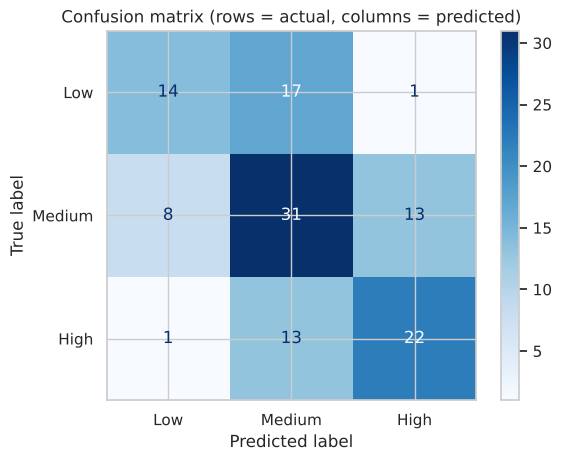

              precision    recall  f1-score   support

         Low       0.61      0.44      0.51        32
      Medium       0.51      0.60      0.55        52
        High       0.61      0.61      0.61        36

    accuracy                           0.56       120
   macro avg       0.58      0.55      0.56       120
weighted avg       0.57      0.56      0.56       120



In [31]:
cm = confusion_matrix(test["level_code"], pred, labels=[0, 1, 2])
ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Blues")
plt.title("Confusion matrix (rows = actual, columns = predicted)")
plt.show()
print(classification_report(test["level_code"], pred, target_names=labels))

**Reading the results:**
- The diagonal of the confusion matrix counts correct predictions.
- Mistakes are almost always between **neighboring** levels (Low↔Medium, Medium↔High); Low is rarely confused with High.
- Precision and recall are reported for each level: recall for Low tells you what share of truly low-performing students the model catches.

### 8.1 Performance metrics summary

Accuracy is only one measure. This table adds measures that account for class imbalance, chance agreement, the ordering of the levels, and the quality of the predicted probabilities, each compared with a baseline that ignores the predictors.

#### Cell: Performance metrics vs a baseline

**What this cell does.** Computes six performance measures for the model on the test set and for a baseline that always predicts the most common level with the overall class probabilities.

**The code, line by line:**
- **Accuracy**: share classified correctly.
- **Balanced accuracy** (`balanced_accuracy_score`): the average recall across the three levels, so a model cannot score well by ignoring the smaller levels.
- **Macro F1** (`f1_score(..., average="macro")`): the F1 score of each level, averaged with equal weight.
- **Cohen's kappa** (`cohen_kappa_score(..., weights="linear")`): agreement beyond chance, from 0 (no better than chance) to 1 (perfect). Linear weights give partial credit for being one level off, which suits ordered levels.
- **Within one level**: share of predictions that are correct or off by one level.
- **Log loss** (`log_loss`): judges the predicted **probabilities**, not just the chosen level. Confident wrong predictions are penalized heavily. Lower is better.
- `prior` holds the class shares from the training data; the baseline predicts those probabilities for every student. `baseline_class` always guesses the most common level (Medium).

**Why it matters.** Different metrics expose different weaknesses. Accuracy can look fine while a small class is ignored; balanced accuracy and macro F1 catch that. Log loss shows whether the probabilities can be trusted, which matters if decisions use them.

**How to read the output.** Higher is better for every row except log loss. See the paragraph below.

In [32]:
from sklearn.metrics import balanced_accuracy_score, f1_score, cohen_kappa_score, log_loss

y_true = test["level_code"]
prior = train["level_code"].value_counts(normalize=True).sort_index().values   # baseline probabilities
baseline_class = np.full(len(test), train["level_code"].mode()[0])                # always guess Medium

perf = pd.DataFrame({
    "Model (test set)": {
        "Accuracy": accuracy_score(y_true, pred),
        "Balanced accuracy": balanced_accuracy_score(y_true, pred),
        "Macro F1": f1_score(y_true, pred, average="macro"),
        "Cohen's kappa (linear weights)": cohen_kappa_score(y_true, pred, weights="linear"),
        "Within one level (%)": (np.abs(y_true.values - pred) <= 1).mean() * 100,
        "Log loss (lower = better)": log_loss(y_true, probs.values, labels=[0, 1, 2])},
    "Baseline": {
        "Accuracy": accuracy_score(y_true, baseline_class),
        "Balanced accuracy": balanced_accuracy_score(y_true, baseline_class),
        "Macro F1": f1_score(y_true, baseline_class, average="macro"),
        "Cohen's kappa (linear weights)": 0.0,
        "Within one level (%)": (np.abs(y_true.values - baseline_class) <= 1).mean() * 100,
        "Log loss (lower = better)": log_loss(y_true, np.tile(prior, (len(test), 1)), labels=[0, 1, 2])},
}).round(3)
perf

,Model (test set),Baseline
Accuracy,0.558,0.433
Balanced accuracy,0.548,0.333
Macro F1,0.556,0.202
Cohen's kappa (linear weights),0.409,0.000
Within one level (%),98.333,100.000
Log loss (lower = better),0.881,1.076


**Interpretation.** The model beats the baseline on every measure except one. **Accuracy** is 55.8% vs 43.3% for always guessing Medium. **Balanced accuracy** (the average of the recall for each level, which does not reward ignoring small classes) is 0.55, compared with 0.33 for the baseline, which only ever gets Medium right. **Macro F1** (0.56 vs 0.20) treats the three levels equally. **Cohen's kappa** measures agreement beyond chance; with linear weights it also gives partial credit for near misses (Medium instead of High). The value of 0.41 indicates moderate agreement, while the baseline scores 0 by definition. **98.3% of predictions are within one level** of the truth: the model almost never confuses Low with High. (The baseline scores 100% here only because Medium is never more than one level from anything, which shows why no single metric is enough.) Finally, **log loss** judges the predicted probabilities themselves; it drops from 1.08 for the baseline to 0.88, so the probabilities are more informative than the overall class shares. Overall the model is clearly useful but far from perfect, which is expected when a continuous score is cut into three bands.

## 9. Fairness metrics

A model can be accurate overall and still work worse for some groups of students. If a model like this one were used to decide who gets tutoring or an early-warning email, those differences would matter. **Fairness metrics** compare the model's behavior across groups.

**Groups we compare:**
- `first_generation`: first-generation college students vs others. This is the main background characteristic in the data.
- `works_part_time`: students with a job vs without, a rough proxy for financial pressure.

**Why cross-validation?** The test set has only about 26–33 first-generation students, so group-level rates from it would be very noisy. Instead we use **5-fold cross-validation**: the data is split into 5 parts; each part is predicted by a model trained on the other 4. Every one of the 600 students then gets a prediction from a model that never saw them, giving larger and more reliable groups.

There is no single definition of fairness, and some definitions conflict with each other. We report a couple of common ones and discuss what they mean.

**Fairness metrics for a classification model.** Suppose students predicted **Low** would be flagged for extra support. Then:

| Metric | Question it answers | Fair if |
| --- | --- | --- |
| **Accuracy by group** | Is the model equally accurate for each group? | Accuracies are similar |
| **Demographic parity** (flag rate) | Are both groups flagged at the same rate? | Flag rates are similar; **disparate impact ratio** (lower rate ÷ higher rate) ≥ 0.8, the common "80% rule" |
| **Equal opportunity** (true positive rate) | Of the students who truly are Low, does each group get flagged at the same rate? | TPRs are similar |
| **Equalized odds** (TPR and false positive rate) | Also: of students who are *not* Low, is each group wrongly flagged at the same rate? | Both TPRs and FPRs are similar |

#### Cell: Cross-validated predictions for fairness

**What this cell does.** Gives every student a predicted level from a model trained without them, using 5-fold cross-validation, and marks who is truly Low and who would be flagged.

**The code, line by line:**
- `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` splits the students into 5 groups, each with the same mix of Low, Medium and High.
- Each round fits the model on 4 groups and predicts the 5th; missing values are filled with that round's training medians.
- `fold_model.predict(te).values.argmax(axis=1)` picks the most likely level for each held-out student.
- `truly_low` marks students who are actually Low; `flagged` marks students the model predicts as Low (those who would receive support).

**Why it matters.** Fairness compares subgroups that are small in a 120-student test set (only about 8–24 truly Low students per group). Cross-validation uses all 600 students, so the comparisons are much more reliable.

**How to read the output.** The cross-validated accuracy (about 0.52) should be similar to the test accuracy, which confirms the predictions are comparable.

In [33]:
from sklearn.model_selection import StratifiedKFold

cv = df.copy()
cv["level_code"] = cv["performance_level"].map(level_codes)
cv["cv_pred"] = -1
for train_idx, test_idx in StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(cv, cv["level_code"]):
    tr, te = cv.iloc[train_idx].copy(), cv.iloc[test_idx].copy()
    fold_medians = tr[numeric_cols].median()
    tr[numeric_cols] = tr[numeric_cols].fillna(fold_medians)
    te[numeric_cols] = te[numeric_cols].fillna(fold_medians)
    fold_model = smf.mnlogit(formula, data=tr).fit(maxiter=200, disp=0)
    cv.loc[cv.index[test_idx], "cv_pred"] = fold_model.predict(te).values.argmax(axis=1)

cv["truly_low"] = cv["level_code"] == 0
cv["flagged"] = cv["cv_pred"] == 0
print(f"Cross-validated accuracy, all students: {(cv.level_code == cv.cv_pred).mean():.3f}")

Cross-validated accuracy, all students: 0.515


#### Cell: Fairness metrics by group

**What this cell does.** For each group, computes accuracy, the share truly Low, the flag rate, the true positive rate and the false positive rate, then summarizes the gaps.

**The code, line by line:**
- **accuracy**: share of the group classified correctly.
- **actually Low (%)**: the group's true base rate. Needed to judge whether a higher flag rate is justified.
- **flag rate (%)**: share predicted Low (**demographic parity**).
- **TPR**: of the group's truly Low students, the % flagged (**equal opportunity**).
- **FPR**: of the group's students who are *not* Low, the % wrongly flagged. TPR and FPR together form **equalized odds**.
- The summary series gives the gaps (second group − first group) and the **disparate impact ratio** = lower flag rate ÷ higher flag rate. A ratio below 0.8 fails the "80% rule," a common screening threshold borrowed from U.S. employment guidelines.
- The final table shows both groups' gaps side by side.

**Why it matters.** Each metric captures a different idea of fairness. Looking at several together, alongside the true base rates, shows whether a difference reflects reality or the model's errors.

**How to read the output.** Gaps near 0 and a disparate impact ratio of at least 0.8 suggest similar treatment. Pay particular attention to FPR gaps: they show one group being wrongly flagged more often.

In [34]:
def classification_fairness(data, group_col, labels):
    rows = []
    for value, label in labels.items():
        g = data[data[group_col] == value]
        rows.append({"group": label, "students": len(g),
                     "accuracy": (g.level_code == g.cv_pred).mean(),
                     "actually Low (%)": g.truly_low.mean() * 100,
                     "flag rate (%)": g.flagged.mean() * 100,
                     "TPR: Low students flagged (%)": g[g.truly_low].flagged.mean() * 100,
                     "FPR: non-Low students flagged (%)": g[~g.truly_low].flagged.mean() * 100})
    table = pd.DataFrame(rows).set_index("group")
    rates = table["flag rate (%)"]
    summary = {"accuracy gap": table.accuracy.iloc[1] - table.accuracy.iloc[0],
               "flag rate gap (points)": rates.iloc[1] - rates.iloc[0],
               "disparate impact ratio": rates.min() / rates.max(),
               "TPR gap (points)": table.iloc[1, 4] - table.iloc[0, 4],
               "FPR gap (points)": table.iloc[1, 5] - table.iloc[0, 5]}
    return table.round(3), pd.Series(summary).round(3)

fg_table, fg_gaps = classification_fairness(cv, "first_generation", {0: "Not first-gen", 1: "First-gen"})
work_table, work_gaps = classification_fairness(cv, "works_part_time", {0: "No job", 1: "Works part-time"})
print("By first-generation status"); display(fg_table)
print("By part-time work"); display(work_table)
pd.DataFrame({"first_generation": fg_gaps, "works_part_time": work_gaps})

By first-generation status


,students,accuracy,actually Low (%),flag rate (%),TPR: Low students flagged (%),FPR: non-Low students flagged (%)
group,,,,,,
Not first-gen,408,0.495,25.245,20.833,39.806,14.426
First-gen,192,0.557,29.688,25.000,50.877,14.074


By part-time work


,students,accuracy,actually Low (%),flag rate (%),TPR: Low students flagged (%),FPR: non-Low students flagged (%)
group,,,,,,
No job,319,0.580,22.571,17.868,45.833,9.717
Works part-time,281,0.441,31.317,27.046,42.045,20.207


,first_generation,works_part_time
accuracy gap,0.062,-0.139
flag rate gap (points),4.167,9.178
disparate impact ratio,0.833,0.661
TPR gap (points),11.071,-3.788
FPR gap (points),-0.352,10.491


#### Cell: Fairness chart

**What this cell does.** Plots accuracy, flag rate, TPR and FPR for the four groups.

**The code, line by line:**
- One panel per metric; purple = comparison group, orange = group of interest. Each purple/orange pair should be compared with each other, not across pairs.

**Why it matters.** A quick visual check of where the model treats groups differently.

**How to read the output.** Look for pairs of bars with clearly different heights, especially in the FPR panel.

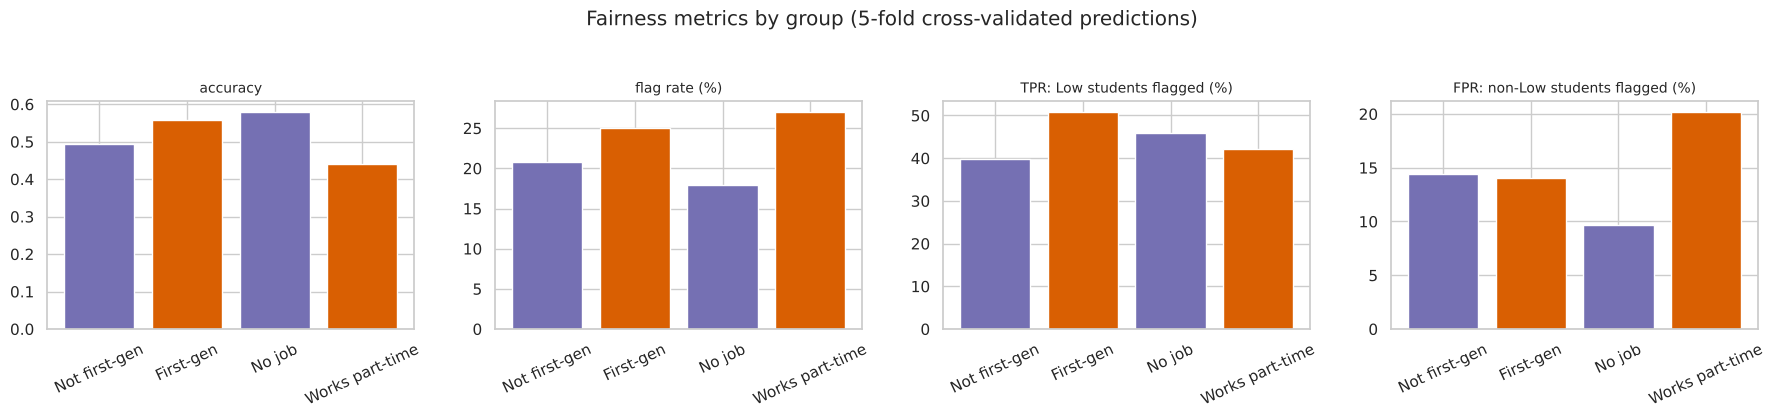

In [35]:
metrics = ["accuracy", "flag rate (%)", "TPR: Low students flagged (%)", "FPR: non-Low students flagged (%)"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, metric in zip(axes, metrics):
    vals = pd.concat([fg_table[metric], work_table[metric]])
    ax.bar(vals.index, vals.values, color=["#7570b3", "#d95f02", "#7570b3", "#d95f02"])
    ax.set_title(metric, fontsize=10); ax.tick_params(axis="x", rotation=25)
plt.suptitle("Fairness metrics by group (5-fold cross-validated predictions)", y=1.04)
plt.tight_layout()
plt.show()

**Interpretation.** The results differ for the two groups.

**First-generation status: no clear unfairness.** The model is slightly *more* accurate for first-generation students (55.7% vs 49.5%). They are flagged a bit more often (25.0% vs 20.8%), and they are also more often truly Low (29.7% vs 25.2%), so the difference largely tracks a real difference. The disparate impact ratio is 0.83, which passes the 80% rule. On equal opportunity, the model catches more truly Low first-generation students (51% vs 40%), and false alarms are almost identical (14.1% vs 14.4%).

**Part-time work: a real fairness concern.** The model is much **less accurate for students who work** (44.1% vs 58.0%). They are flagged as Low far more often (27.0% vs 17.9%; disparate impact ratio 0.66, which **fails** the 80% rule). Some of this reflects reality, since working students are more often truly Low (31.3% vs 22.6%). But the equalized-odds check shows the problem is not only a difference in base rates. Among students who are **not** Low, working students are wrongly flagged about **twice as often** (20.2% vs 9.7%), while truly Low working students are caught slightly *less* often (42% vs 46%). The model leans on work hours as a warning sign: it raises false alarms for working students who are doing fine without catching the ones who are struggling better.

**What this means.** If this model were used to send students to tutoring, many working students who are doing fine would be flagged unnecessarily. That could be harmless (extra support) or harmful (stigma, wasted time), depending on how flags are used. Options include checking the model separately for this group, adjusting the flagging threshold per group, revisiting how work hours enter the model (Section 7.5 already found its relationship is curved), and above all keeping a human in the loop.

**Limits of these checks.** Groups are still modest in size (57 truly Low first-generation students), so gaps of a few points can be chance. The fairness definitions can conflict: when base rates differ, as here, a model generally cannot equalize flag rates and error rates at the same time. Choosing which matters most is a values decision, not only a statistical one.

## 10. Discussion

### Answer to the research question

The model clearly beats guessing: **test accuracy is 55.8%**, compared with **43.3%** for always guessing the largest class (Medium). Overall fit is solid for this kind of model (McFadden pseudo R² = 0.22; likelihood-ratio test p < 0.001).

Its mistakes are almost all between **neighboring** levels: of 120 test students, only 2 were confused between Low and High. Recall is weakest for **Low (0.44)**: the model misses more than half of truly low-performing students, usually labeling them Medium.

### Which variables matter most?

The likelihood-ratio tests rank the variables by how much the model's fit drops when each one is removed:

| Rank | Variable | LR chi-square | Odds ratio, High vs Low | What it means |
| --- | --- | --- | --- | --- |
| 1 | Study hours per week | 70.1 | 1.38 per hour | 5 more hours ≈ 5 times the odds of High rather than Low |
| 2 | Prior GPA | 58.9 | 11.6 per GPA point | Half a GPA point ≈ 3.4 times the odds |
| 3 | Attendance | 49.2 | 1.13 per 1% | 10 points more attendance ≈ 3.5 times the odds |
| 4 | Major | 33.4 | 7.8 for Data Science vs Business | Large but imprecise (wide confidence interval) |
| 5 | Study group | 18.7 | 4.4 | Members have about 4 times the odds of High |
| 6 | Sleep | 14.4 | 1.74 per hour | Each extra hour ≈ 1.7 times the odds |
| — | Work hours | 5.7 (p = 0.058) | 0.96 per hour | Significant only for High vs Low |
| — | First-generation, commute | 2.5 and 1.2 | — | Not significant |

**Why the standardized ranking looks different:** in the standardized table, Data Science and study group appear near the top because they are 0/1 variables, so their coefficient is the full group difference rather than a 1-SD change. The likelihood-ratio ranking puts every variable on the same footing and is the better guide to importance.

**A clear pattern:** every effect is larger for **High vs Low** than for **Medium vs Low**. The levels are ordered, and the predictors push students steadily up the scale. An **ordinal logistic regression** (statsmodels `OrderedModel`) would capture this with one coefficient per variable and is worth comparing.

### Comparing with the linear regression notebook

The same variables lead in both models: study hours, prior GPA, attendance, study group and sleep. Turning the exam score into three categories throws away information (an 80 and a 99 are both High), which is one reason classification accuracy is only moderate.

### Fairness (Section 9)

The model shows no clear unfairness by first-generation status, but it treats **working students** differently: accuracy is 44% for them vs 58% for others, and working students who are not Low are wrongly flagged as Low about twice as often (20% vs 10%). Any real use of this model would need that gap addressed, and a human reviewing the flags.

### Limitations

- **Association, not causation**: the model shows which students tend to land in each level, not what would happen if a student changed a habit.
- **Moderate recall for Low** matters if the goal is to identify students who need support. Lowering the probability needed to predict Low would catch more of them, at the cost of more false alarms.
- **Median imputation** of missing values, and **simulated data** used for teaching.

### Try next (template exercises)

1. Fit an ordinal model (`from statsmodels.miscmodels.ordinal_model import OrderedModel`) and compare accuracy and interpretation.
2. Predict "Low" whenever P(Low) > 0.35 and see how recall and precision for Low change.
3. Drop the non-significant variables and check whether test accuracy changes.
4. Swap in your own dataset: change the file name, research question, target coding, `numeric_cols` and the formula, then rerun every cell.